# Obesity Level Prediction Using Supervised Machine Learning

Problem type:Multiclass classification

Dataset: Estimation of Obesity Levels Based on Eating Habits and Physical Condition

Algorithms:Logistic Regression and Random Forest Classifier

Group:9

Logistic Regression by: Kumarasinghe LHSV MS26924182

Random Forest by :  IWMHD BANDARA MS26929514


# Objective
Predict the obesity-level category (`NObeyesdad`)



In [16]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [17]:
# Load the dataset
DATA_PATH = "ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


\nColumn names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

None

\nMissing values per column:


Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

\nObesity-level class counts:


NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

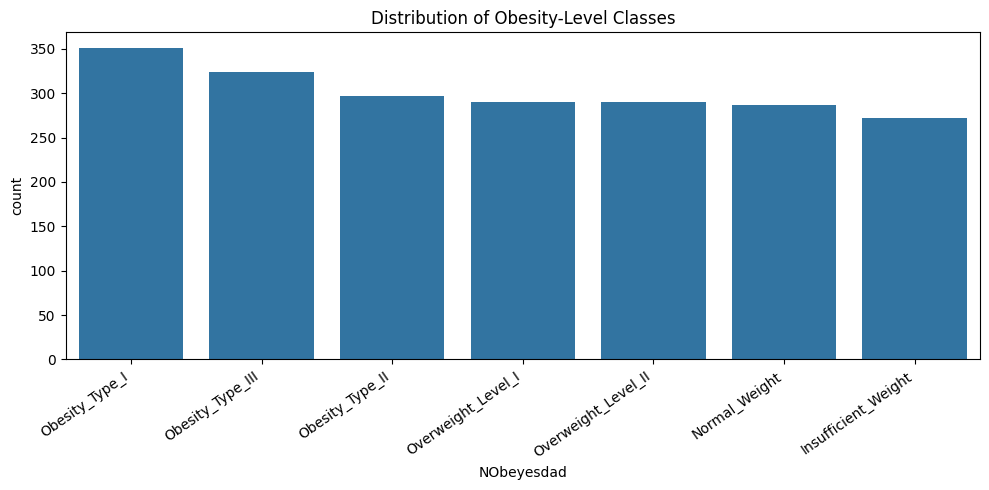

In [18]:

display(df.info())
print("\\nMissing values per column:")
display(df.isnull().sum())
print("\\nObesity-level class counts:")
display(df["NObeyesdad"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="NObeyesdad", order=df["NObeyesdad"].value_counts().index)
plt.title("Distribution of Obesity-Level Classes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [19]:
TARGET = "NObeyesdad"
X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training instances:", X_train.shape[0])
print("Testing instances:", X_test.shape[0])
print("Number of input features:", X.shape[1])
print("Number of classes:", y.nunique())

Training instances: 1688
Testing instances: 423
Number of input features: 16
Number of classes: 7


In [20]:
#Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression results")
print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))
print("Precision (macro):", round(precision_score(y_test, logistic_predictions, average="macro", zero_division=0), 4))
print("Recall (macro):", round(recall_score(y_test, logistic_predictions, average="macro", zero_division=0), 4))
print("F1-score (macro):", round(f1_score(y_test, logistic_predictions, average="macro", zero_division=0), 4))
print("\\nClassification report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

Logistic Regression results
Accuracy: 0.8747
Precision (macro): 0.8707
Recall (macro): 0.8724
F1-score (macro): 0.8708
\nClassification report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.92      1.00      0.96        54
      Normal_Weight       0.81      0.74      0.77        58
     Obesity_Type_I       0.88      0.91      0.90        70
    Obesity_Type_II       0.94      0.97      0.95        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.74      0.74      0.74        58
Overweight_Level_II       0.81      0.76      0.79        58

           accuracy                           0.87       423
          macro avg       0.87      0.87      0.87       423
       weighted avg       0.87      0.87      0.87       423



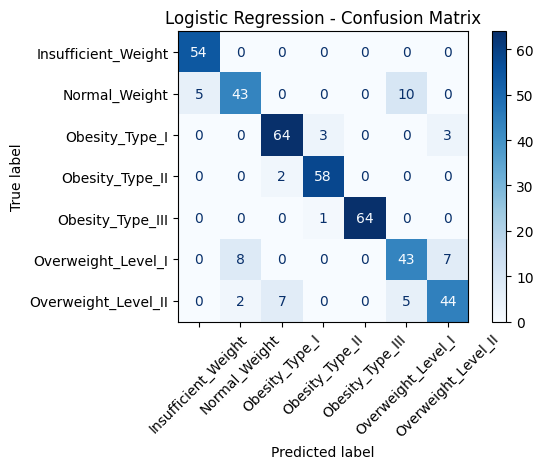

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions, xticks_rotation=45, cmap="Blues"
)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest results")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision (macro):", round(precision_score(y_test, rf_predictions, average="macro", zero_division=0), 4))
print("Recall (macro):", round(recall_score(y_test, rf_predictions, average="macro", zero_division=0), 4))
print("F1-score (macro):", round(f1_score(y_test, rf_predictions, average="macro", zero_division=0), 4))
print("\\nClassification report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

Random Forest results
Accuracy: 0.9314
Precision (macro): 0.9353
Recall (macro): 0.9295
F1-score (macro): 0.9313
\nClassification report:
                     precision    recall  f1-score   support

Insufficient_Weight       1.00      0.93      0.96        54
      Normal_Weight       0.76      0.90      0.83        58
     Obesity_Type_I       0.94      0.96      0.95        70
    Obesity_Type_II       1.00      0.98      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.88      0.84      0.86        58
Overweight_Level_II       0.96      0.91      0.94        58

           accuracy                           0.93       423
          macro avg       0.94      0.93      0.93       423
       weighted avg       0.94      0.93      0.93       423



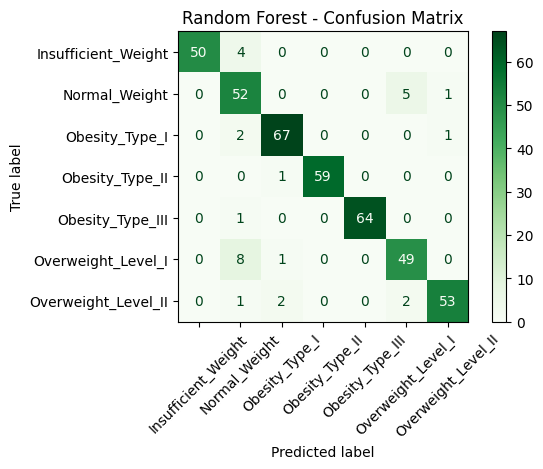

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions, xticks_rotation=45, cmap="Greens"
)
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

,Accuracy,Macro Precision,Macro Recall,Macro F1-score
Algorithm,,,,
Logistic Regression,0.8747,0.8707,0.8724,0.8708
Random Forest,0.9314,0.9353,0.9295,0.9313


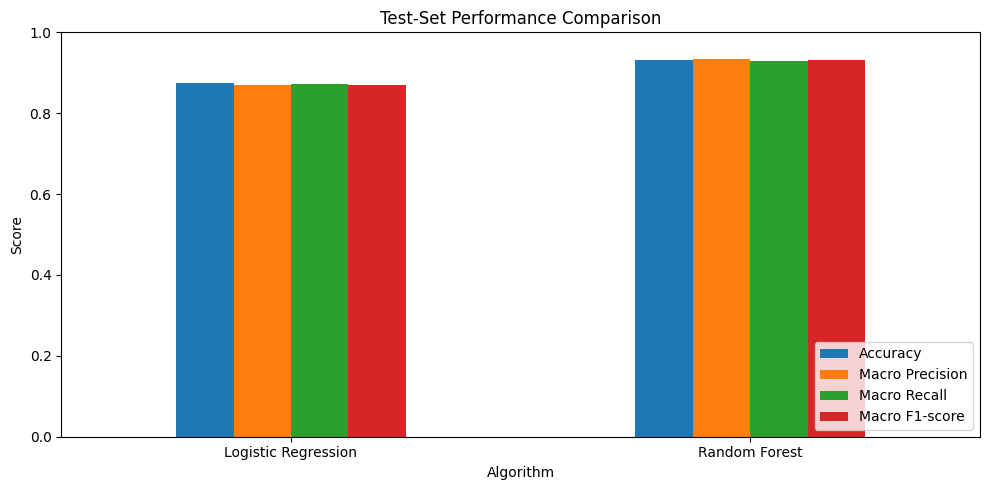

Best model by macro F1-score: Random Forest


In [24]:
results = pd.DataFrame([
    {
        "Algorithm": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, logistic_predictions),
        "Macro Precision": precision_score(y_test, logistic_predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, logistic_predictions, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, logistic_predictions, average="macro", zero_division=0),
    },
    {
        "Algorithm": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Macro Precision": precision_score(y_test, rf_predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, rf_predictions, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, rf_predictions, average="macro", zero_division=0),
    }
]).set_index("Algorithm")

display(results.round(4))

results[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Test-Set Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model = results["Macro F1-score"].idxmax()
print("Best model by macro F1-score:", best_model)